
# Task 2: Time-Series Regression (Remaining Useful Life/RUL)

## 1. Project Overview

### 1.1 Problem Definition

This project focuses on predicting the **Remaining Useful Life (RUL)** of press machines using time‑series sensor measurements collected throughout operational cycles. 

The primary objective is to estimate the number of remaining operating cycles before machine failure occurs, enabling valuable information for maintenance scheduling and reliability management. 

To improve model practicality and stability, the target variable is capped at a **maximum value of one hundred fifty operating cycles**.

$$
RUL_t = \min(T_{\text{failure}} - t, 150)$$

### 1.2 Project Objectives

1. Perform Exploratory Data Analysis (EDA).
2. Conduct data preprocessing and RUL label generation.
3. Transform time-series data into sliding windows.
4. Develop and compare sequence-based Deep Learning models.
5. Establish a non-Deep Learning baseline.
6. Perform machine-level validation.
7. Estimate prediction uncertainty.
8. Evaluate models using RMSE and Asymmetric Score.

### 1.3 Evaluation Metrics

- Root Mean Squared Error (RMSE).
- Asymmetric Score.

### 1.4 Project Requirements

- At least two sequence-based Deep Learning architectures.
- One non-Deep Learning baseline.
- Machine-level train-validation split.
- Prediction intervals using Monte Carlo Dropout or Ensemble.
- Final RUL prediction for test machines.



## 2. Library Imports

Several Python libraries are imported to facilitate data processing, file operations, archive handling, and formatted output generation, forming the foundation for subsequent project implementations:

- **`Pandas`:** Used for data manipulation and tabular data analysis.
- **`Pathlib`:** Used to manage file and directory paths.
- **`IPython.display`:** Provides functions to display formatted outputs and render Markdown content within the notebook.
- **`ZipFile`:** Used to access and read files directly from a ZIP archive without manually extracting its contents.

Additional libraries will be imported in subsequent sections depending on the requirements of data analysis, preprocessing, visualization, and model development.


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from zipfile import ZipFile
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

## 3. Dataset Understanding

This section provides an overview of the dataset structure, variable definitions, and initial verification of the training and testing datasets.

### 3.1 Dataset Archive Inventory

The following code inspects the compressed dataset archive and builds a formatted summary table displaying each file name along with its corresponding storage size in megabytes.

In [64]:
project_dir = Path.cwd() 
if project_dir.name.lower() == "kode":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

zip_candidates = [
    data_dir / "data_uts_dl.zip",
    project_dir / "data_uts_dl.zip",
    project_dir.parent / "data_uts_dl.zip"
]

zip_path = next(
    (path for path in zip_candidates if path.exists()),
    None
)

if zip_path is not None:
    with ZipFile(zip_path, "r") as zip_ref:
        files = [
            item for item in zip_ref.infolist()
            if not item.is_dir()
        ]

        inventory = pd.DataFrame([
            {
                "No": idx + 1,
                "File Name": file.filename,
                "File Size (MB)": file.file_size / (1024 * 1024)
            }
            for idx, file in enumerate(files)
        ])

    display(
        inventory.style
        .set_caption("Dataset Inventory")
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("text-align", "center"),
                    ("font-size", "14px"),
                    ("font-weight", "bold"),
                    ("caption-side", "top"),
                    ("padding-bottom", "8px")
                ]
            },
            {
                "selector": "th",
                "props": [("text-align", "center")]
            }
        ])
        .format({"File Size (MB)": "{:.3f}"})
        .set_properties(**{"text-align": "center"})
        .set_properties(
            subset=["File Name"],
            **{"text-align": "left"}
        )
        .hide(axis="index")
    )

else:
    print("ZIP archive not found.")
    print("Checking extracted dataset files in data/ directory.")

No,File Name,File Size (MB)
1,klasifikasi_train_meta.csv,1.733
2,klasifikasi_test.npz,58.271
3,kamus_data.md,0.002
4,klasifikasi_train.npz,170.985
5,rul_test.csv.gz,3.936
6,rul_train.csv.gz,19.401
7,clustering_meta.csv,0.573
8,klasifikasi_test_meta.csv,0.457
9,clustering.npz,124.222


### 3.2 Data Dictionary Inspection

The following code extracts and renders the official data dictionary from the archive so that all variable definitions and target labeling rules remain clearly documented in the notebook.

In [65]:
dict_candidates = [
    project_dir / "kamus_data.md", 
    data_dir / "kamus_data.md",
    project_dir.parent / "kamus_data.md"
]

dict_path = next(
    (path for path in dict_candidates if path.exists()),
    None
)

if zip_path is not None:
    with ZipFile(zip_path, "r") as zip_ref:
        dict_file = next(
            name for name in zip_ref.namelist() 
            if name.lower().endswith("kamus_data.md")
        )

        dict_text = zip_ref.read(dict_file).decode("utf-8-sig", errors="replace")
    display(Markdown(dict_text))

elif dict_path is not None:
    display(Markdown(dict_path.read_text(encoding="utf-8")))

else:
    print("Data dictionary not found.")

# Kamus data UTS Deep Learning

Semua kelompok menerima data yang sama. Label data uji tidak dibagikan.

## Tugas 1: klasifikasi_train.npz, klasifikasi_test.npz, klasifikasi_*_meta.csv

Satu sampel per unit produk dari pabrik komponen fiktif. Baris ke-i di berkas meta
memakai `indeks` = i pada array di berkas npz.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), foto permukaan produk |
| `sensor` | Array float16 (N, 3, 128): suhu (C), getaran (relatif), arus (A) selama penekanan. NaN berarti data tidak terekam |
| id_unit | ID unit produk |
| lini | Lini produksi (A atau B) |
| shift | Shift produksi |
| id_mesin | Mesin penekan |
| batch_material | Batch bahan baku |
| kelas | Label: normal, gores, noda, retak, gelembung, las_dingin, kontaminasi. Hanya di data latih |

Label data latih berasal dari inspektur dan tidak dijamin bebas salah.

## Tugas 2: rul_train.csv.gz dan rul_test.csv.gz

Log per siklus untuk mesin press fiktif. Data latih berisi riwayat sampai mesin rusak.
Data uji berhenti pada titik acak sebelum rusak.

| Kolom | Keterangan |
| --- | --- |
| id_unit | ID mesin |
| siklus | Nomor siklus sejak mesin mulai dipakai |
| setel_1, setel_2, setel_3 | Pengaturan operasi pada siklus itu |
| s01-s21 | Bacaan sensor. NaN berarti bacaan hilang |

Label: sisa umur pakai (RUL) = jumlah siklus tersisa sampai rusak, dipotong pada 150
(sisa umur di atas 150 siklus dihitung 150). Di data latih, siklus terakhir tiap unit adalah
siklus saat rusak, jadi labelnya dihitung sendiri. Prediksi RUL dibuat pada siklus terakhir
tiap unit di data uji.

## Tugas 3: clustering.npz dan clustering_meta.csv

Sampel material dari laboratorium fiktif, tanpa label.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), citra mikrostruktur dari mikroskop |
| `spektrum` | Array float16 (N, 128), spektrum komposisi |
| id_sampel | ID sampel |
| mikroskop | Mikroskop yang dipakai (M1 atau M2) |


### 3.3 Loading and Initial Dataset Verification

The RUL training and testing datasets were loaded into Pandas DataFrames, and their size, columns, and machine IDs were checked to ensure the data was correct before performing exploratory data analysis.

In [66]:
train_path = data_dir / "rul_train.csv.gz"
test_path = data_dir / "rul_test.csv.gz"

if zip_path is not None:
    with ZipFile(zip_path, "r") as zip_ref:
        train_file = next(
            name for name in zip_ref.namelist()
            if name.lower().endswith("rul_train.csv.gz")
        )

        test_file = next(
            name for name in zip_ref.namelist()
            if name.lower().endswith("rul_test.csv.gz")
        )

        train_path.write_bytes(zip_ref.read(train_file))
        test_path.write_bytes(zip_ref.read(test_file))

if not train_path.exists() or not test_path.exists():
    raise FileNotFoundError(
        "Place rul_train.csv.gz and rul_test.csv.gz inside data/."
    )

train = pd.read_csv(train_path, compression="gzip")
test = pd.read_csv(test_path, compression="gzip")

#### 3.3.1 Dataset Verification

The following code verifies dataset dimensions, machine counts, and required column availability, while detecting missing columns to ensure data integrity before further analysis.

In [68]:
expected_columns = (
    ["id_unit", "siklus", "setel_1", "setel_2", "setel_3"]
    + [f"s{i:02d}" for i in range(1, 22)]
)

missing_train = [
    column for column in expected_columns
    if column not in train.columns
]

missing_test = [
    column for column in expected_columns
    if column not in test.columns
]

data = {
    "Training Dataset Shape": f"{train.shape[0]} rows x {train.shape[1]} columns",
    "Testing Dataset Shape": f"{test.shape[0]} rows x {test.shape[1]} columns",
    "Training Machines": f"{train['id_unit'].nunique()}",
    "Testing Machines": f"{test['id_unit'].nunique()}",
    "Missing Training Columns": ", ".join(missing_train) if missing_train else "None",
    "Missing Testing Columns": ", ".join(missing_test) if missing_test else "None"
}

width = max(len(label) for label in data)

for label, value in data.items():
    print(f"{label:<{width}} : {value}")

if missing_train or missing_test:
    raise ValueError("Required dataset columns are missing.")

Training Dataset Shape   : 254174 rows x 26 columns
Testing Dataset Shape    : 51692 rows x 26 columns
Training Machines        : 900
Testing Machines         : 300
Missing Training Columns : None
Missing Testing Columns  : None


#### 3.3.2 Dataset Summary 

The following code summarizes the training and testing datasets by displaying their records, columns, and unique machines in a structured comparison table.

In [69]:
dataset_summary = pd.DataFrame([
    {
        "Dataset": "Training",
        "Number of Records": len(train),
        "Number of Columns": len(train.columns),
        "Unique Machines": train["id_unit"].nunique()
    },
    {
        "Dataset": "Testing",
        "Number of Records": len(test),
        "Number of Columns": len(test.columns),
        "Unique Machines": test["id_unit"].nunique()
    }
])

display(
    dataset_summary.style
    .format({
        "Number of Records": "{}", 
        "Number of Columns": "{}",
        "Unique Machines": "{}"
    })
    .set_caption(
        "Dataset Structural Summary"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center")
            ]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

Dataset,Number of Records,Number of Columns,Unique Machines
Training,254174,26,900
Testing,51692,26,300


#### 3.3.3 Training Dataset Sample 

The following code extracts and formats the first three training records, allowing initial examination of machine settings and sensor measurement values.

In [71]:
sample_columns = [
    "id_unit",
    "siklus",
    "setel_1",
    "setel_2",
    "setel_3",
    "s01",
    "s02",
    "s03"
]

display(
    train[sample_columns].head(3).style
    .format(precision=3)
    .set_caption(
        "Sample Training Records"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center")
            ]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03
3,1,20.001,0.701,100.000,1107.746,569.289,991.700
3,2,34.996,0.842,100.000,1071.040,587.821,1013.673
3,3,0.001,-0.001,100.000,1130.132,585.094,998.221


#### 3.3.4 Testing Dataset Sample 

The following code extracts and formats the first three testing records, enabling verification of input features and target column availability.

In [72]:
display(
    test[sample_columns].head(3).style
    .format(precision=3)
    .set_caption(
        "Sample Testing Records"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "center")
            ]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

id_unit,siklus,setel_1,setel_2,setel_3,s01,s02,s03
1,1,20.001,0.703,100.000,1109.194,566.947,992.053
1,2,9.998,0.252,100.000,1091.159,578.471,1002.437
1,3,42.002,0.837,100.000,1086.341,557.209,990.383


## 4. Exploratory Data Analysis (EDA)

This section conducts exploratory data analysis to examine machine-level characteristics, assess dataset quality, analyze operating settings and sensor distributions, and identify relationships and outliers.

### 4.1 Machine Identification and Operating Cycle Analysis

This subsection examines machine counts, identifier ranges, and operating cycle distributions across training and testing datasets to understand machine-level data characteristics.

#### 4.1.1 Training Machine Identification Summary

The following code summarizes machine identifiers and operating cycle ranges in the training dataset by calculating machine counts and basic cycle statistics.

In [74]:
setting_columns = ["setel_1", "setel_2", "setel_3"]
sensor_columns = [f"s{i:02d}" for i in range(1, 22)]

train_cycle = (
    train.groupby("id_unit")
    .agg(
        jumlah_siklus=("siklus", "count"),
        siklus_min=("siklus", "min"),
        siklus_max=("siklus", "max")
    )
    .reset_index()
)

data = {
    "Training Unique Machines": f"{train['id_unit'].nunique()}",
    "Training Minimum Machine ID": train["id_unit"].min(),
    "Training Maximum Machine ID": train["id_unit"].max(),
    "Training Minimum Cycle": train["siklus"].min(),
    "Training Maximum Cycle": train["siklus"].max(),
}

width = max(len(label) for label in data)

for label, value in data.items():
    print(f"{label:<{width}} : {value}")

Training Unique Machines    : 900
Training Minimum Machine ID : 3
Training Maximum Machine ID : 1199
Training Minimum Cycle      : 1
Training Maximum Cycle      : 778


#### 4.1.2 Testing Machine Identification Summary

The following code summarizes machine identifiers and operating cycle ranges in the testing dataset by calculating machine counts and basic cycle statistics.

In [76]:
test_cycle = (
    test.groupby("id_unit")
    .agg(
        jumlah_siklus=("siklus", "count"),
        siklus_min=("siklus", "min"),
        siklus_max=("siklus", "max")
    )
    .reset_index()
)

test_summary = {
    "Testing Unique Machines": f"{test['id_unit'].nunique()}",
    "Testing Minimum Machine ID": test["id_unit"].min(),
    "Testing Maximum Machine ID": test["id_unit"].max(),
    "Testing Minimum Cycle": test["siklus"].min(),
    "Testing Maximum Cycle": test["siklus"].max(),
}

width = max(len(label) for label in test_summary)

for label, value in test_summary.items():
    print(f"{label:<{width}} : {value}")

Testing Unique Machines    : 300
Testing Minimum Machine ID : 1
Testing Maximum Machine ID : 1200
Testing Minimum Cycle      : 1
Testing Maximum Cycle      : 455


#### 4.1.3 Operating Cycle Distribution Statistics

The following code generates descriptive statistics for machine operating cycles in both datasets to examine cycle distribution characteristics and variability.

In [77]:
cycle_summary = pd.DataFrame([
    {
        "Dataset": "Training",
        **train_cycle["jumlah_siklus"].describe().to_dict()
    },
    {
        "Dataset": "Testing",
        **test_cycle["jumlah_siklus"].describe().to_dict()
    }
])

cycle_summary = cycle_summary.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

display(
    cycle_summary.style
    .format({
        "Count": "{:.3f}",
        "Mean": "{:.3f}",
        "Std": "{:.3f}",
        "Minimum": "{:.3f}",
        "Q1": "{:.3f}",
        "Median": "{:.3f}",
        "Q3": "{:.3f}",
        "Maximum": "{:.3f}"
    })
    .set_caption(
        "Operating Cycle Statistics by Dataset"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

Dataset,Count,Mean,Std,Minimum,Q1,Median,Q3,Maximum
Training,900.000,282.416,84.630,133.000,224.000,265.000,323.000,778.000
Testing,300.000,172.307,72.684,50.000,117.000,162.500,212.000,455.000


#### 4.1.4 Sample Machine Operating Cycle Records

The following code displays sample machine operating cycle records to illustrate the structure and cycle information associated with individual machines.

In [80]:
display(
    train_cycle.head(10).style
    .format({
        "id_unit": "{}",
        "jumlah_siklus": "{}",
        "siklus_min": "{}",
        "siklus_max": "{}"
    })
    .set_caption(
        "Sample Machine Operating Cycle Records"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

id_unit,jumlah_siklus,siklus_min,siklus_max
3,318,1,318
4,222,1,222
5,600,1,600
7,238,1,238
9,219,1,219
10,237,1,237
11,312,1,312
12,311,1,311
13,199,1,199
14,172,1,172


#### 4.1.5 Machine and Cycle Variable Identification

The following code identifies the machine and cycle variables by presenting their data types, unique values, and functional roles.

In [81]:
column_roles = pd.DataFrame({
    "Column": ["id_unit", "siklus"],
    "Data Type": [
        str(train["id_unit"].dtype),
        str(train["siklus"].dtype)
    ],
    "Unique Values": [
        train["id_unit"].nunique(),
        train["siklus"].nunique()
    ],
    "Role": [
        "Machine identifier",
        "Temporal operating cycle"
    ]
})

display(
    column_roles.style
    .set_caption(
        "Identification of Machine and Cycle Variables"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .set_properties(
        subset=["Role"],
        **{"text-align": "left"}
    )
    .hide(axis="index")
)

Column,Data Type,Unique Values,Role
id_unit,int64,900,Machine identifier
siklus,int64,778,Temporal operating cycle


#### 4.1.6 Duplicate Record Verification

The following code checks for duplicate machine-cycle records in the training and testing datasets to verify data consistency and uniqueness.

In [82]:
data = {
    "Training Duplicate Records": train.duplicated(
        ["id_unit", "siklus"]
    ).sum(),
    "Testing Duplicate Records": test.duplicated(
        ["id_unit", "siklus"]
    ).sum()
}

width = max(len(label) for label in data)

for label, value in data.items():
    print(f"{label:<{width}} : {value}")

Training Duplicate Records : 0
Testing Duplicate Records  : 0


### 4.2 Missing Values and Sensor Informativeness

This subsection evaluates data completeness and sensor characteristics by analyzing missing values and evaluating sensor informativeness to identify features suitable for further analysis.

#### 4.2.1 Missing Values Summary

The following code analyzes missing values in the training and testing datasets by calculating missing counts and percentages for each feature and presenting the results in a formatted table.

In [84]:
mv_table = pd.DataFrame({
    "Train Missing": train.isna().sum(),
    "Train Missing (%)": train.isna().mean() * 100,
    "Test Missing": test.isna().sum(),
    "Test Missing (%)": test.isna().mean() * 100
})

mv_table = mv_table.sort_values(
    "Train Missing (%)",
    ascending=False
)

display(
    mv_table.style
    .format({
        "Train Missing": "{}",
        "Train Missing (%)": "{:.3f}",
        "Test Missing": "{}",
        "Test Missing (%)": "{:.3f}"
    })
    .set_caption(
        "Missing Values Summary"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

Train Missing,Train Missing (%),Test Missing,Test Missing (%)
5371,2.113,1013,1.960
5272,2.074,1008,1.950
5235,2.060,1044,2.020
5235,2.060,992,1.919
5219,2.053,1035,2.002
5215,2.052,1082,2.093
5193,2.043,976,1.888
5173,2.035,1025,1.983
5162,2.031,1009,1.952
5156,2.029,1053,2.037


#### 4.2.2 Sensor Informativeness Analysis

The following code evaluates sensor informativeness using unique values, missing data, mean, and standard deviation to identify constant or non-informative sensors.

In [87]:
unique_count = train[sensor_columns].nunique(dropna=True)
sensor_std = train[sensor_columns].std()

sensor_info = pd.DataFrame({
    "Unique Values": unique_count,
    "Missing Count": train[sensor_columns].isna().sum(),
    "Missing (%)": train[sensor_columns].isna().mean() * 100,
    "Mean": train[sensor_columns].mean(),
    "Std": sensor_std
})

conditions = [
    sensor_info["Unique Values"] == 0,
    sensor_info["Unique Values"] == 1
]

choices = [
    "All values missing",
    "Constant / Non-informative"
]

sensor_info["Status"] = np.select(
    conditions,
    choices,
    default="Informative"
)

informative_sc = sensor_info.index[
    sensor_info["Status"] == "Informative"
].tolist()

sensor_info_display = (
    sensor_info
    .rename_axis("Sensor")
    .reset_index()
)

display(
    sensor_info_display.style
    .format({
        "Unique Values": "{}",
        "Missing Count": "{}",
        "Missing (%)": "{:.3f}",
        "Mean": "{:.3f}",
        "Std": "{:.3f}"
    })
    .set_caption(
        "Sensor Informativeness Analysis"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

Sensor,Unique Values,Missing Count,Missing (%),Mean,Std,Status
s01,66416,5081,1.999,1101.646,17.760,Informative
s02,49790,5272,2.074,579.598,15.929,Informative
s03,73424,5116,2.013,1005.494,23.054,Informative
s04,66366,5215,2.052,1133.476,17.625,Informative
s05,4860,5109,2.010,168.545,9.489,Informative
s06,39558,5235,2.060,1310.545,8.695,Informative
s07,33031,5219,2.053,723.626,6.827,Informative
s08,33082,5130,2.018,779.354,6.859,Informative
s09,39186,5173,2.035,498.012,25.157,Informative
s10,34473,5138,2.021,803.320,17.416,Informative


### 4.3 Operating Settings and Sensor Distribution

This subsection analyzes the descriptive statistics and distributions of operating settings and sensor readings to understand their variability and measurement patterns.

#### 4.3.1 Operating Settings Statistics

The following code calculates descriptive statistics for the operating settings to summarize their central tendencies, dispersion, and overall data distribution.

In [88]:
setting_stats = train[setting_columns].describe().T

display(
    setting_stats.style
    .format(precision=3)
    .set_caption(
        "Operating Settings Descriptive Statistics"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
)

,count,mean,std,min,25%,50%,75%,max
setel_1,254174.000,22.023,14.210,-0.008,10.000,24.993,35.000,42.008
setel_2,254174.000,0.542,0.313,-0.007,0.250,0.695,0.839,0.849
setel_3,254174.000,93.357,14.886,60.000,100.000,100.000,100.000,100.000


#### 4.3.2 Sensor Readings Statistics

The following code calculates descriptive statistics for sensor readings to examine their distribution, variability, and measurement characteristics across observations.

In [20]:
sensor_stats = train[sensor_columns].describe().T

display(
    sensor_stats.style
    .format(precision=3)
    .set_caption(
        "Sensor Readings Descriptive Statistics"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
)

,count,mean,std,min,25%,50%,75%,max
s01,249093.000,1101.646,17.760,1042.699,1089.314,1100.198,1115.557,1161.239
s02,248902.000,579.598,15.929,537.791,569.502,580.095,586.165,619.762
s03,249058.000,1005.494,23.054,943.024,988.301,999.592,1017.862,1081.733
s04,248959.000,1133.476,17.625,1079.085,1124.402,1133.505,1145.767,1196.050
s05,249065.000,168.545,9.489,156.897,161.767,162.578,173.896,187.159
s06,248939.000,1310.545,8.695,1267.150,1304.219,1309.544,1315.358,1358.938
s07,248955.000,723.626,6.827,683.143,719.193,723.476,728.895,754.713
s08,249044.000,779.354,6.859,750.189,775.063,780.140,784.097,810.489
s09,249001.000,498.012,25.157,444.323,489.275,497.380,515.702,543.874
s10,249036.000,803.320,17.416,771.549,783.859,802.901,819.451,839.647


#### 4.3.3 Distribution of **`setel_1`**

The following code visualizes the distribution of the first operating setting using a histogram to examine its frequency patterns and spread.

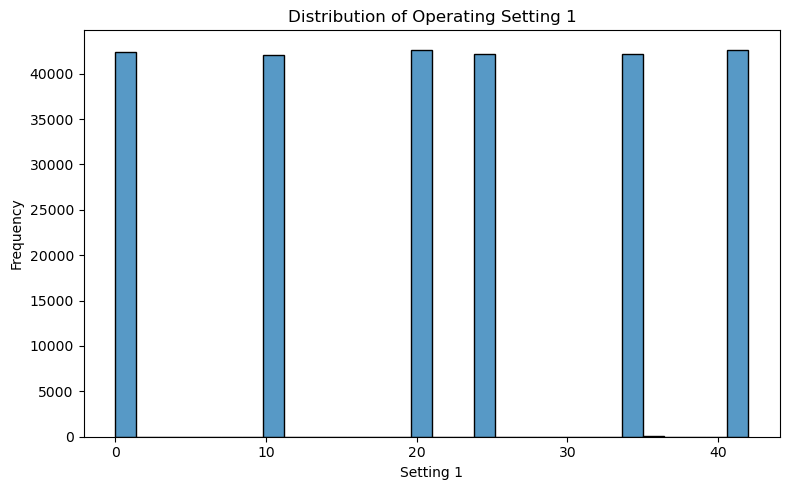

In [89]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=train,
    x="setel_1",
    bins=30,
    ax=ax
)

ax.set_title("Distribution of Operating Setting 1")
ax.set_xlabel("Setting 1")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 4.3.4 Distribution of **`setel_2`**

The following code visualizes the distribution of the second operating setting using a histogram to assess its frequency distribution and variability.

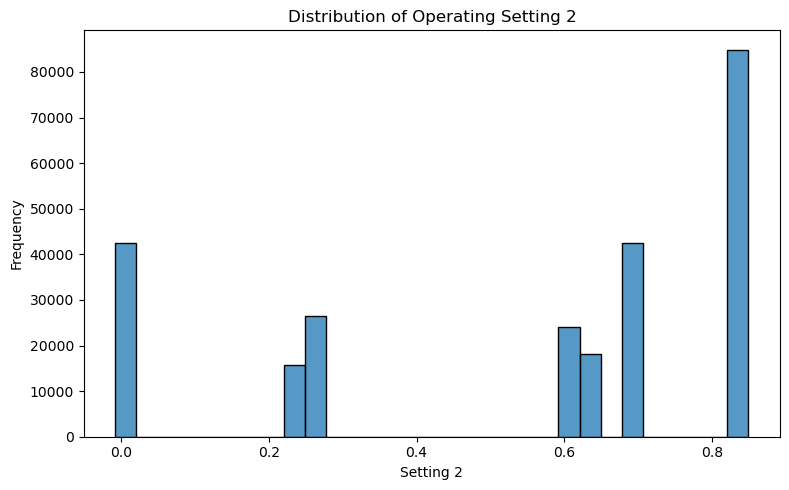

In [90]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=train,
    x="setel_2",
    bins=30,
    ax=ax
)

ax.set_title("Distribution of Operating Setting 2")
ax.set_xlabel("Setting 2")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 4.3.5 Distribution of **`setel_3`**

The following code visualizes the distribution of the third operating setting using a histogram to assess its frequency distribution and variability.

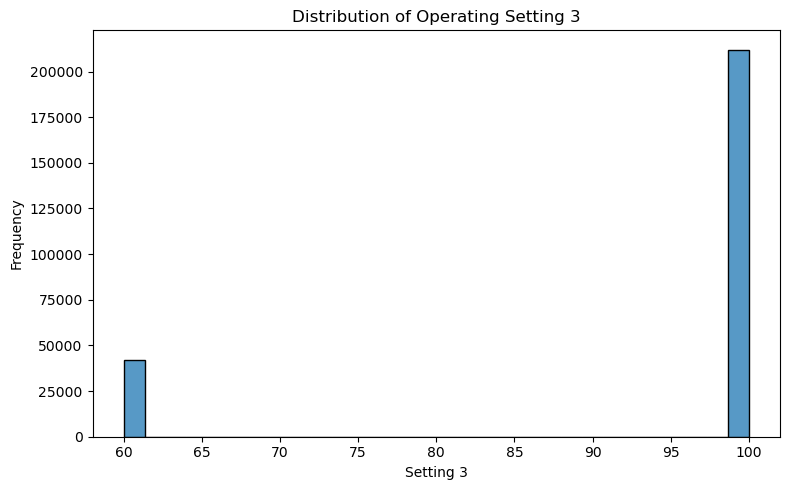

In [91]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=train,
    x="setel_3",
    bins=30,
    ax=ax
)

ax.set_title("Distribution of Operating Setting 3")
ax.set_xlabel("Setting 3")
ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 4.3.6 Standardized Sensor Distribution

The following code standardizes sensor readings and visualizes their distributions using boxplots to compare variability patterns across informative sensors in the dataset.

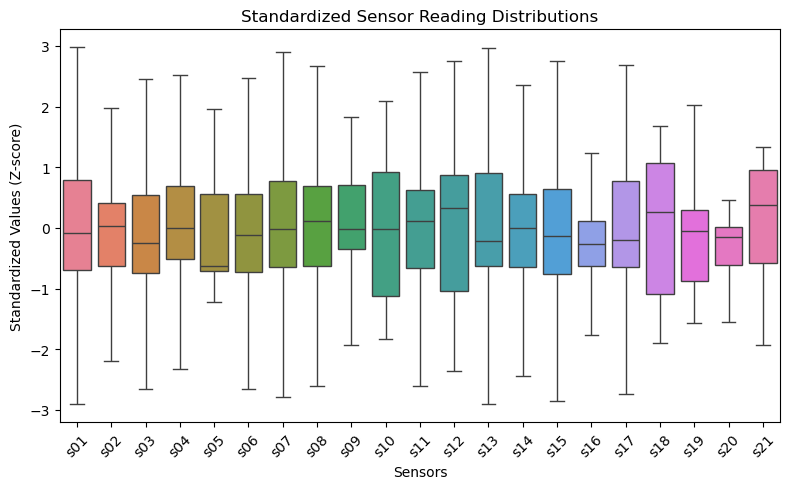

In [92]:
sensor_count = sensor_info.index[ 
    sensor_info["Std"].fillna(0) > 0
].tolist()

sensor_zscore = (
    train[sensor_count] -
    train[sensor_count].mean()
) / train[sensor_count].std() #mean every sensor is 0, standard deviation is 1

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=sensor_zscore,
    showfliers=False,
    ax=ax
)

ax.set_title("Standardized Sensor Reading Distributions")
ax.set_xlabel("Sensors")
ax.set_ylabel("Standardized Values (Z-score)")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 4.4 Operating Settings Relationships and Outlier Detection

This subsection investigates correlations between operating settings and sensor measurements while identifying potential outliers and examining sensor behavior across operating cycles.

#### 4.4.1 Correlation Heatmap

The following code computes correlations between operating settings and sensor measurements, then visualizes the relationships using a heatmap for easier interpretation.

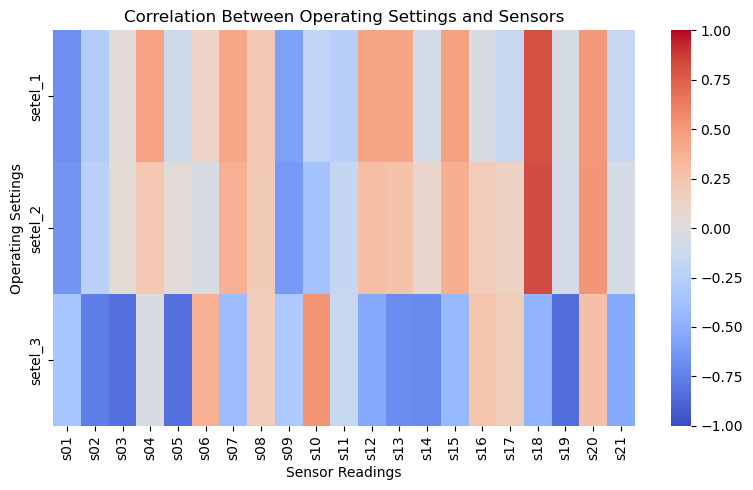

In [93]:
corr_matrix = train[
    setting_columns + sensor_columns
].corr()

setting_sensor_corr = corr_matrix.loc[
    setting_columns,
    sensor_columns
]

fig, ax = plt.subplots(figsize=(8, 5))

sns.heatmap(
    setting_sensor_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    ax=ax
)

ax.set_title(
    "Correlation Between Operating Settings and Sensors"
)
ax.set_xlabel("Sensor Readings")
ax.set_ylabel("Operating Settings")

plt.tight_layout()
plt.show()

#### 4.4.2 Potential Sensor Outliers

The following code identifies potential sensor outliers using the interquartile range method and summarizes their frequency across sensor measurements.

In [96]:
Q1 = train[sensor_columns].quantile(0.25)
Q3 = train[sensor_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (train[sensor_columns] < lower_bound) |
    (train[sensor_columns] > upper_bound)
)

valid_counts = train[sensor_columns].count()

outlier_table = pd.DataFrame({
    "Outlier Count": outlier_mask.sum(),
    "Valid Values": valid_counts,
    "Outlier (%)": (
        outlier_mask.sum() / valid_counts * 100
    )
})

outlier_table = (
    outlier_table
    .rename_axis("Sensor")
    .reset_index()
)

display(
    outlier_table.style
    .format({
        "Outlier Count": "{}",
        "Valid Values": "{}",
        "Outlier (%)": "{:.3f}"
    })
    .set_caption(
        "Potential Sensor Outlier Analysis Using Interquartile Range (IQR)"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)

Sensor,Outlier Count,Valid Values,Outlier (%)
s01,33,249093,0.013
s02,946,248902,0.380
s03,128,249058,0.051
s04,350,248959,0.141
s05,0,249065,0.000
s06,2064,248939,0.829
s07,1656,248955,0.665
s08,888,249044,0.357
s09,231,249001,0.093
s10,0,249036,0.000


#### 4.4.3 Sensor Readings Across Operating Cycles

The following code visualizes selected sensor readings across operating cycles to identify potential spikes and temporal measurement patterns.

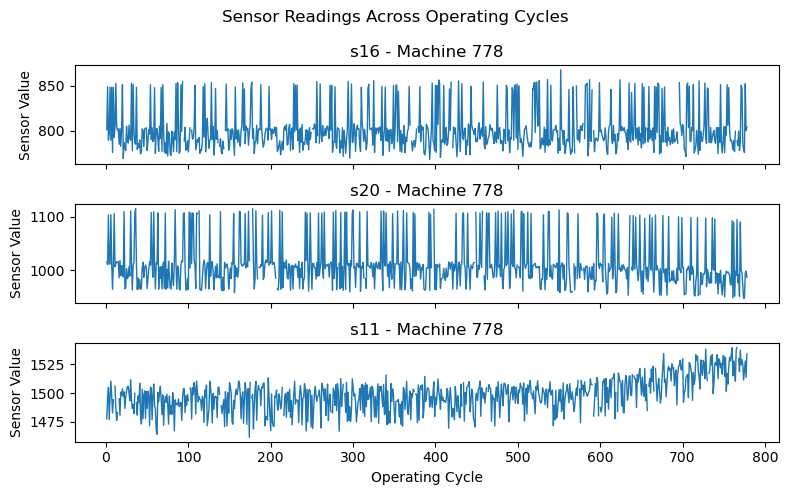

In [97]:
sample_unit = train_cycle.loc[
    train_cycle["jumlah_siklus"].idxmax(),
    "id_unit"
]

sample_data = (
    train[train["id_unit"] == sample_unit]
    .sort_values("siklus")
)

selected_sensors = (
    outlier_table
    .sort_values("Outlier Count", ascending=False)
    .head(3)["Sensor"]
    .tolist()
)

fig, axes = plt.subplots(
    len(selected_sensors),
    1,
    figsize=(8, 5),
    sharex=True
)

axes = np.atleast_1d(axes)

for index, sensor in enumerate(selected_sensors):

    ax = axes[index]

    ax.plot(
        sample_data["siklus"],
        sample_data[sensor],
        linewidth=1
    )

    ax.set_title(f"{sensor} - Machine {sample_unit}")
    ax.set_ylabel("Sensor Value")

axes[-1].set_xlabel("Operating Cycle")

fig.suptitle(
    "Sensor Readings Across Operating Cycles"
)

plt.tight_layout()
plt.show()

## 5. Remaining Useful Life (RUL) Label Generation

This section generates and validates Remaining Useful Life (RUL) labels for the training dataset, then examines their characteristics and distribution for predictive modeling.

### 5.1 RUL Label Calculation

The following code calculates RUL labels for each training record using machine failure cycles and applies a maximum limit of 150 cycles.

In [98]:
training_rul = train.sort_values(
    ["id_unit", "siklus"]
).copy()

failure_cycle = (
    training_rul.groupby("id_unit")["siklus"]
    .transform("max")
)

training_rul["rul"] = (
    failure_cycle - training_rul["siklus"]
).clip(lower=0, upper=150)

print("----- RUL Summary -----")
data = {
    "Training Records": f"{len(training_rul)}",
    "Unique Machines": f"{training_rul['id_unit'].nunique()}",
    "Minimum RUL": training_rul["rul"].min(),
    "Maximum RUL": training_rul["rul"].max()
}

width = max(len(label) for label in data)

for label, value in data.items():
    print(f"{label:<{width}} : {value}")

----- RUL Summary -----
Training Records : 254174
Unique Machines  : 900
Minimum RUL      : 0
Maximum RUL      : 150


### 5.2 Machine-Level RUL Summary

The following code summarizes machine-level RUL information by calculating operating cycles, failure cycles, record counts, and corresponding RUL values.

In [99]:
rul_summary = (
    training_rul.groupby("id_unit")
    .agg(
        first_cycle=("siklus", "min"),
        failure_cycle=("siklus", "max"),
        total_records=("siklus", "count"),
        initial_rul=("rul", "first"),
        final_rul=("rul", "last")
    )
    .reset_index()
)

display(
    rul_summary.head(10).style
    .format({
        "id_unit": "{}",
        "first_cycle": "{}",
        "failure_cycle": "{}",
        "total_records": "{}",
        "initial_rul": "{}",
        "final_rul": "{}"
    })
    .set_caption(
        "Machine-Level RUL Summary"
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("text-align", "center"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("caption-side", "top"),
                ("padding-bottom", "8px")
            ]
        },
        {
            "selector": "th",
            "props": [("text-align", "center")]
        }
    ])
    .set_properties(**{"text-align": "center"})
    .hide(axis="index")
)


id_unit,first_cycle,failure_cycle,total_records,initial_rul,final_rul
3,1,318,318,150,0
4,1,222,222,150,0
5,1,600,600,150,0
7,1,238,238,150,0
9,1,219,219,150,0
10,1,237,237,150,0
11,1,312,312,150,0
12,1,311,311,150,0
13,1,199,199,150,0
14,1,172,172,150,0


### 5.3 RUL Label Verification 

The following code verifies RUL labels by checking allowable ranges, final RUL values, and consistency between failure records and machines.

In [103]:
last_records = (
    training_rul.groupby("id_unit")
    .tail(1)
)

checks = {
    "RUL within 0-150": training_rul["rul"].between(0, 150).all(),
    "Final RUL equals zero": last_records["rul"].eq(0).all(),
    "Failure records match machine count": (
        len(last_records) == training_rul["id_unit"].nunique()
    ),
}

width = max(len(label) for label in checks)

for label, passed in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"{label:<{width}} : [{status}]")

if not all(checks.values()):
    raise AssertionError("RUL label verification failed.")

print("-" * (width + 10))
print("Overall Verification : ALL CHECKS PASSED")

RUL within 0-150                    : [PASS]
Final RUL equals zero               : [PASS]
Failure records match machine count : [PASS]
---------------------------------------------
Overall Verification : ALL CHECKS PASSED


### 5.4 RUL Distribution

The following code visualizes the distribution of generated RUL labels using a histogram to examine their frequency across training records.

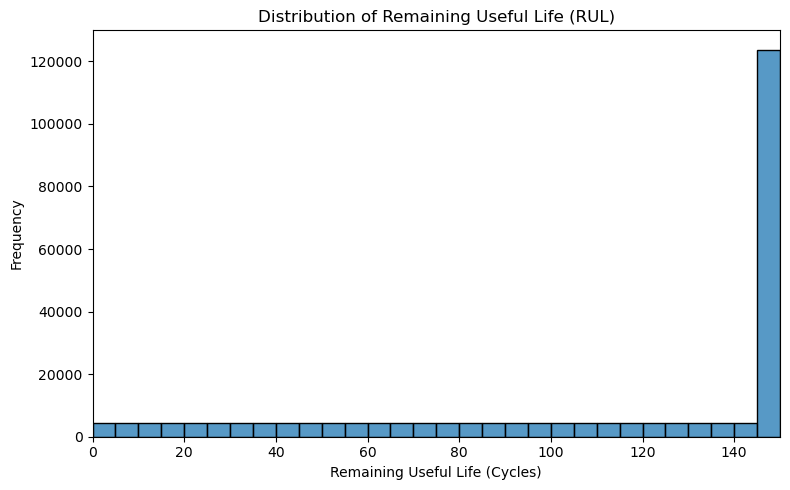

In [104]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=training_rul,
    x="rul",
    bins=30,
    ax=ax
)

ax.set_title(
    "Distribution of Remaining Useful Life (RUL)"
)

ax.set_xlabel("Remaining Useful Life (Cycles)")
ax.set_ylabel("Frequency")
ax.set_xlim(0, 150)

plt.tight_layout()
plt.show()

## 6. Sliding Window Generation

This section transforms machine operating histories into fixed‑length time‑series sequences using a sliding window approach, including preprocessing, sequence generation, dataset splitting, and verification procedures.

### 6.1 Feature Selection and Window COnfiguration

The following code defines the operating settings and sensor measurements used as input features, along with the sliding window size and step interval for sequence generation.

In [ ]:
def display_section6_table(dataframe, caption, format_dict=None):

    display(
        dataframe.style
        .format(format_dict or {})
        .set_caption(caption)
        .set_table_styles([
            {
                "selector": "caption",
                "props": [
                    ("text-align", "center"),
                    ("font-size", "14px"),
                    ("font-weight", "bold"),
                    ("caption-side", "top"),
                    ("padding-bottom", "8px")
                ]
            },
            {
                "selector": "th",
                "props": [
                    ("text-align", "center")
                ]
            }
        ])
        .set_properties(**{"text-align": "center"})
        .hide(axis="index")
    )


setting_cols = ["setel_1", "setel_2", "setel_3"]
sensor_cols = [f"s{i:02d}" for i in range(1, 22)]
feature_cols = setting_cols + sensor_cols

WINDOW_SIZE = 30
WINDOW_STEP = 5

assert len(feature_cols) == 24 #measuring there are 24 features, 3 settings and 21 sensors
assert set(feature_cols).issubset(training_rul.columns)
assert set(feature_cols).issubset(test.columns)

configuration_summary = pd.DataFrame({
    "Parameter": [
        "Operating Settings",
        "Sensor Readings",
        "Total Input Features",
        "Window Size",
        "Window Step"
    ],
    "Value": [
        len(setting_cols),
        len(sensor_cols),
        len(feature_cols),
        WINDOW_SIZE,
        WINDOW_STEP
    ]
})

display_section6_table(
    configuration_summary,
    "Sliding Window Configuration",
    {"Value": "{}"}
)

Parameter,Value
Operating Settings,3
Sensor Readings,21
Total Input Features,24
Window Size,30
Window Step,5


### 6.2 Machine-Level Training and Validation Split

The following code separates machines into training and validation subsets to prevent data leakage and ensure that observations from the same machine cannot appear in both subsets.

In [ ]:
splitter = GroupShuffleSplit( #training_rul split into 80% training and 20% validation sets based on unique machine identifiers
    n_splits=1,
    test_size=0.2,
    random_state=42   
)

train_idx, val_idx = next(
    splitter.split(
        training_rul,
        groups=training_rul["id_unit"]
    )
) #grouping based on "id_unit" 

units_train = training_rul.iloc[train_idx].copy() #copy the selected rows to two separate dataframes (training set)
units_val = training_rul.iloc[val_idx].copy() #copy the selected rows to two separate dataframes (validation set)

units_train = (
    units_train
    .sort_values(["id_unit", "siklus"])
    .reset_index(drop=True)
)

units_val = (
    units_val
    .sort_values(["id_unit", "siklus"])
    .reset_index(drop=True)
) #sort based on "id_unit" and "siklus" and reset the index for both dataframes

train_machine_ids = set( units_train["id_unit"].unique())
val_machine_ids = set( units_val["id_unit"].unique())

total_labeled_machines = training_rul["id_unit"].nunique()

assert train_machine_ids.isdisjoint(val_machine_ids)

assert (
    len(train_machine_ids | val_machine_ids)
    == total_labeled_machines
)

machine_split_summary = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Machine Overlap",
        "Total"
    ],
    "Machine Count": [
        len(train_machine_ids),
        len(val_machine_ids),
        len(train_machine_ids & val_machine_ids),
        total_labeled_machines
    ]
})

display_section6_table(
    machine_split_summary,
    "Machine-Level Training and Validation Split",
    {"Machine Count": "{}"}
)

Dataset,Machine Count
Training,720
Validation,180
Machine Overlap,0
Total,900


In [31]:
train_part = train_part.sort_values(["id_unit", "siklus"])
val_part = val_part.sort_values(["id_unit", "siklus"])
test_part = test.sort_values(["id_unit", "siklus"]).copy()

train_part[feature_cols] = (
    train_part.groupby("id_unit")[feature_cols].ffill()
)

feature_medians = train_part[feature_cols].median().fillna(0)

def impute_features(df):
    df = df.copy()

    df[feature_cols] = (
        df.groupby("id_unit")[feature_cols].ffill()
    )

    df[feature_cols] = df[feature_cols].fillna(feature_medians)

    return df

train_part = impute_features(train_part)
val_part = impute_features(val_part)
test_part = impute_features(test_part)

scaler = StandardScaler()

scaler.fit(train_part[feature_cols])

for df in [train_part, val_part, test_part]:
    df.loc[:, feature_cols] = scaler.transform(
        df[feature_cols]
    ).astype(np.float32)

print("Missing values after imputation:")
print("Train:", train_part[feature_cols].isna().sum().sum())
print("Validation:", val_part[feature_cols].isna().sum().sum())
print("Test:", test_part[feature_cols].isna().sum().sum())


Missing values after imputation:
Train: 0
Validation: 0
Test: 0


In [ ]:
def create_window(values, end_idx, window_size):

    values = np.asarray(values, dtype=np.float32)

    if len(values) == 0:
        raise ValueError("Machine history is empty.")

    start_idx = max(0, end_idx - window_size + 1)

    window = values[start_idx:end_idx + 1]

    if len(window) < window_size:

        padding_size = window_size - len(window)

        padding = np.repeat(
            values[0:1],
            padding_size,
            axis=0
        )

        window = np.concatenate(
            [padding, window],
            axis=0
        )

    return window.astype(np.float32)

In [ ]:
X_train_list = []
y_train_list = []

for machine_id, group in train_part.groupby("id_unit", sort=False):

    values = group[feature_cols].to_numpy(dtype=np.float32)
    labels = group["rul"].to_numpy(dtype=np.float32)

    end_indices = list(range(0, len(group), WINDOW_STEP))

    if end_indices[-1] != len(group) - 1:
        end_indices.append(len(group) - 1)

    for end_idx in end_indices:

        window = create_window(
            values,
            end_idx,
            WINDOW_SIZE
        )

        X_train_list.append(window)
        y_train_list.append(labels[end_idx])

X_train_seq = np.stack(X_train_list)
y_train_seq = np.asarray(y_train_list, dtype=np.float32)

print("Training windows:", X_train_seq.shape)
print("Training labels:", y_train_seq.shape)


Training windows: (41622, 30, 24)
Training labels: (41622,)


In [34]:
rng = np.random.default_rng(42)

X_val_list = []
y_val_list = []

val_machine_ids_list = []
val_cutoff_cycles = []

for machine_id, group in val_part.groupby("id_unit", sort=False):

    values = group[feature_cols].to_numpy(dtype=np.float32)
    labels = group["rul"].to_numpy(dtype=np.float32)

    # Randomly select a cutoff before failure
    if len(group) > 1:
        end_idx = int(rng.integers(0, len(group) - 1))
    else:
        end_idx = 0

    window = create_window(
        values,
        end_idx,
        WINDOW_SIZE
    )

    X_val_list.append(window)
    y_val_list.append(labels[end_idx])

    val_machine_ids_list.append(machine_id)
    val_cutoff_cycles.append(group.iloc[end_idx]["siklus"])

X_val_seq = np.stack(X_val_list)
y_val_seq = np.asarray(y_val_list, dtype=np.float32)

print("Validation windows:", X_val_seq.shape)
print("Validation labels:", y_val_seq.shape)

Validation windows: (180, 30, 24)
Validation labels: (180,)


In [35]:
X_test_list = []

test_machine_ids = []
test_cutoff_cycles = []

for machine_id, group in test_part.groupby("id_unit", sort=False):

    values = group[feature_cols].to_numpy(dtype=np.float32)

    end_idx = len(group) - 1

    window = create_window(
        values,
        end_idx,
        WINDOW_SIZE
    )

    X_test_list.append(window)

    test_machine_ids.append(machine_id)
    test_cutoff_cycles.append(group.iloc[end_idx]["siklus"])

X_test_seq = np.stack(X_test_list)

print("Test windows:", X_test_seq.shape)
print("Test machines:", len(test_machine_ids))

Test windows: (300, 30, 24)
Test machines: 300


In [36]:
assert X_train_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert X_val_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))
assert X_test_seq.shape[1:] == (WINDOW_SIZE, len(feature_cols))

assert len(test_machine_ids) == test["id_unit"].nunique()

assert np.isfinite(X_train_seq).all()
assert np.isfinite(X_val_seq).all()
assert np.isfinite(X_test_seq).all()

assert train_machine_ids.isdisjoint(val_machine_ids)

print("Sliding window generation completed successfully.")
print("Machine-based validation: PASSED")
print("Test machine retention: PASSED")
print("Sequence integrity: PASSED")

Sliding window generation completed successfully.
Machine-based validation: PASSED
Test machine retention: PASSED
Sequence integrity: PASSED
